# MAXMERCH: A/B-тест экрана приоритизации задач мерчендайзера


MAXMERCH — B2B-приложение для планирования визитов мерчендайзеров в торговые точки.

**Задача:** оценить, повышает ли новый экран с группировкой и приоритетами задач долю визитов с выполненными обязательными задачами, не ухудшая операционные метрики.

**Протокол:** 3 000 мерчендайзеров; индивидуальная рандомизация 1:1, стратифицированная по городу, стажу и платформе; 2 недели pre-period и фиксированные 6 недель теста. Группа закрепляется за аккаунтом мерчендайзера; основной анализ — ITT на уровне мерчендайзера.


## 1. Импорт и загрузка данных

В проекте 3 000 мерчендайзеров и более 150 000 строк визитов. Таблицы связаны ключами: `merchandiser_id`, `visit_id`, `outlet_id`, `project_id`.


In [50]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
DATA_DIR = Path('data')
merch = pd.read_csv(DATA_DIR / 'merchandisers.csv')
assign = pd.read_csv(DATA_DIR / 'experiment_assignments.csv')
outlets = pd.read_csv(DATA_DIR / 'outlets.csv')
projects = pd.read_csv(DATA_DIR / 'projects.csv')
visits_raw = pd.read_csv(DATA_DIR / 'visits.csv')
tasks = pd.read_csv(DATA_DIR / 'tasks.csv')
events = pd.read_csv(DATA_DIR / 'events.csv')
print({name: len(frame) for name, frame in {'merchandisers':merch,'assignments':assign,'visits_raw':visits_raw,'tasks':tasks,'events':events}.items()})


{'merchandisers': 3000, 'assignments': 3000, 'visits_raw': 318411, 'tasks': 1176557, 'events': 320122}


## 2. Предварительно зафиксированный протокол и гипотезы

**Основная метрика:** доля запланированных визитов мерчендайзера, где выполнены все обязательные задачи. Отменённые, пропущенные и незавершённые визиты остаются в ITT-знаменателе и дают `0` по основной метрике.

- **H₀:** средняя доля успешных визитов в тестовой и контрольной группах одинакова (Δ = 0).
- **H₁:** средняя доля успешных визитов различается (Δ ≠ 0), двусторонняя проверка.
- **α = 0,05**, мощность планирования **80%**.
- **MDE для бизнес-решения:** +1,0 процентный пункт (п.п.).
- Статистическая значимость оценивается по p-value и 95% ДИ. Практическое решение дополнительно учитывает MDE и защитные метрики.

Поскольку рандомизация на уровне мерчендайзера, повторные визиты нельзя считать независимыми наблюдениями. Основной тест проводится на агрегированной метрике каждого мерчендайзера (Welch t-test). Визитный z-тест показан только как наивная иллюстрация и не используется для решения.

**Правила до старта:** вариант фиксируется на аккаунте; тест длится 6 недель без промежуточных остановок по результату основной метрики; каждый запланированный визит в периоде включается в ITT, no-show и отмены дают 0; exposure анализируется отдельно и не заменяет ITT. Для интерпретации продуктового запуска требуется показ нового экрана минимум в 85% подходящих визитов. SRM проверяем на уровне назначенных сотрудников; p < 0,001 требует расследования до чтения эффекта.

**Защитные пороги:** рост no-start не более +1,0 п.п.; рост app-error и support-ticket rate не более +0,2 п.п. каждый; средняя длительность визита не должна увеличиться более чем на 2 минуты. При нарушении любого порога общий rollout не рекомендуется, даже при положительной основной метрике. Пороги зафиксированы до начала теста.


## 3. Проверка структуры и качества исходных данных

Сначала проверяем ключи, дубликаты, пропуски, даты и соответствие связей. Технические дубликаты визитов удаляются по `visit_id`; отмены и no-show не удаляются, так как они относятся к исходу по ITT.


In [51]:
# Обзор схемы, размеров, ключей и пропусков
quality = pd.DataFrame({
    'rows': {'visits_raw':len(visits_raw),'tasks':len(tasks),'events':len(events)},
    'duplicate_keys': {'visits_raw':int(visits_raw.visit_id.duplicated().sum()),'tasks':int(tasks.task_id.duplicated().sum()),'events':int(events.event_id.duplicated().sum())},
    'missing_cells': {'visits_raw':int(visits_raw.isna().sum().sum()),'tasks':int(tasks.isna().sum().sum()),'events':int(events.isna().sum().sum())}
})
display(quality)
print('Group assignment:', assign.group.value_counts().to_dict())
print('Visit status:', visits_raw.visit_status.value_counts(dropna=False).to_dict())
print('Phase:', visits_raw.phase.value_counts().to_dict())
print('Foreign keys:')
print(' unknown merchandisers:', (~visits_raw.merchandiser_id.isin(merch.merchandiser_id)).sum())
print(' unknown outlets:', (~visits_raw.outlet_id.isin(outlets.outlet_id)).sum())
print(' unknown projects:', (~visits_raw.project_id.isin(projects.project_id)).sum())


,rows,duplicate_keys,missing_cells
visits_raw,318411,476,33416
tasks,1176557,0,147527
events,320122,0,0


Group assignment: {'control': 1500, 'treatment': 1500}
Visit status: {'completed': 301703, 'cancelled': 11260, 'no_show': 5448}
Phase: {'experiment': 238722, 'pre': 79689}
Foreign keys:
 unknown merchandisers: 0
 unknown outlets: 0
 unknown projects: 0


In [52]:
# Предобработка: удаляем только точные дубли visit_id, парсим даты, отмечаем невалидную длительность
visits = visits_raw.drop_duplicates('visit_id', keep='first').copy()
for c in ['scheduled_at','actual_start_at','actual_end_at']:
    visits[c] = pd.to_datetime(visits[c], errors='coerce')
visits['duration_min'] = (visits.actual_end_at - visits.actual_start_at).dt.total_seconds()/60
visits['invalid_duration'] = visits.duration_min.notna() & ((visits.duration_min <= 0) | (visits.duration_min > 240))
# Для duration guardrail не обрезаем выбросы молча: сохраняем валидный флаг, invalid остаётся видимым в аудите.
print(f'Удалено повторных visit_id: {len(visits_raw)-len(visits):,}')
print(f'Уникальные визиты после дедупликации: {len(visits):,}')
print('Missing actual start/end (mostly no-show/cancelled):', visits[['actual_start_at','actual_end_at']].isna().sum().to_dict())
print('Invalid duration count:', int(visits.invalid_duration.sum()))
assert visits.visit_id.is_unique
assert set(assign.group.unique()) == {'control','treatment'}


Удалено повторных visit_id: 476
Уникальные визиты после дедупликации: 317,935
Missing actual start/end (mostly no-show/cancelled): {'actual_start_at': 16683, 'actual_end_at': 16683}
Invalid duration count: 0


## 4. Сборка аналитической таблицы

Результат визита выводится из `tasks.csv`, а не берётся готовым полем: все задачи с `is_required=True` должны иметь статус `completed`. Для каждого назначенного мерчендайзера считаем долю успешных визитов за период эксперимента.


In [53]:
task_rollup = (tasks.assign(is_required=tasks.is_required.astype(bool), is_completed=tasks.task_status.eq('completed'))
    .query('is_required')
    .groupby('visit_id')
    .agg(required_tasks=('task_id','size'), completed_required=('is_completed','sum'))
    .reset_index())
task_rollup['all_required_complete'] = task_rollup.completed_required.eq(task_rollup.required_tasks)
analysis = visits.merge(task_rollup, on='visit_id', how='left', validate='one_to_one')
analysis[['required_tasks','completed_required']] = analysis[['required_tasks','completed_required']].fillna(0)
analysis['all_required_complete'] = analysis.all_required_complete.fillna(False).astype(bool)
analysis = analysis.merge(assign[['merchandiser_id','group']],on='merchandiser_id',how='left',suffixes=('','_assigned'),validate='many_to_one')
# Assignment ledger is the source of truth for ITT, even if a raw visit label were inconsistent.
analysis['group'] = analysis.group_assigned
analysis['scheduled_date'] = analysis.scheduled_at.dt.date
analysis['phase'] = np.where((analysis.scheduled_at >= '2025-09-15') & (analysis.scheduled_at < '2025-10-25'),'experiment','pre')
exp = analysis.loc[analysis.phase.eq('experiment')].copy()
user_metric = (exp.groupby(['merchandiser_id','group'])
    .agg(planned_visits=('visit_id','nunique'), successful_visits=('all_required_complete','sum'),
         completion_rate=('all_required_complete','mean'), visit_minutes=('duration_min','mean'),
         completed_tasks=('completed_required','sum'), required_tasks=('required_tasks','sum'))
    .reset_index())
print(f'Аналитические визиты в эксперименте: {len(exp):,}; пользователи: {user_metric.merchandiser_id.nunique():,}')
display(user_metric.groupby('group').agg(users=('merchandiser_id','nunique'),visits=('planned_visits','sum'),mean_user_completion=('completion_rate','mean'),median_visits=('planned_visits','median')))


Аналитические визиты в эксперименте: 238,363; пользователи: 3,000


,users,visits,mean_user_completion,median_visits
group,,,,
control,1500,118863,0.7032,79.0000
treatment,1500,119500,0.7085,79.0000


## 5. Проверка рандомизации и pre-period

Проверяем размер групп и баланс предэкспериментальных характеристик. p-value баланса не используется как фильтр эксперимента: случайные отличия возможны, важнее заранее заданная схема рандомизации и масштаб различий.


In [54]:
balance = assign.groupby('group').agg(users=('merchandiser_id','nunique'),mean_tenure=('tenure_months','mean')).T
display(balance)
for col in ['city','tenure_band','platform']:
    print(f'\n{col} — доли по группе')
    display(pd.crosstab(assign[col],assign.group,normalize='columns').round(3))
pre = analysis.loc[analysis.phase.eq('pre')].groupby(['merchandiser_id','group']).agg(pre_visits=('visit_id','nunique'),pre_completion=('all_required_complete','mean')).reset_index()
display(pre.groupby('group').agg(users=('merchandiser_id','nunique'),mean_pre_visits=('pre_visits','mean'),mean_pre_completion=('pre_completion','mean')))

# SRM проверяется на уровне назначенных сотрудников, а не визитов
n_total=assign.merchandiser_id.nunique()
n_treatment=int(assign.group.eq('treatment').sum())
srm_p=stats.binomtest(n_treatment,n_total,p=.5,alternative='two-sided').pvalue
print(f'SRM: control={n_total-n_treatment:,}, treatment={n_treatment:,}, p={srm_p:.4f}; порог расследования p<0.001')
team_mix=assign.groupby('team_id').group.nunique()
print(f'Доля команд, где представлены обе группы: {team_mix.eq(2).mean():.1%}; team-level spillover остаётся риском дизайна.')


group,control,treatment
users,"1,500.0000","1,500.0000"
mean_tenure,21.2320,20.8207



city — доли по группе


group,control,treatment
city,,
Aktobe,0.0800,0.0800
Almaty,0.3400,0.3390
Astana,0.2330,0.2330
Atyrau,0.0780,0.0780
Karaganda,0.1100,0.1090
Shymkent,0.1590,0.1610



tenure_band — доли по группе


group,control,treatment
tenure_band,,
0-6m,0.1300,0.1290
19m+,0.4830,0.4830
7-18m,0.3870,0.3880



platform — доли по группе


group,control,treatment
platform,,
Android,0.7800,0.7790
iOS,0.2200,0.2210


,users,mean_pre_visits,mean_pre_completion
group,,,
control,1500,26.5507,0.7090
treatment,1500,26.4973,0.7022


SRM: control=1,500, treatment=1,500, p=1.0000; порог расследования p<0.001
Доля команд, где представлены обе группы: 100.0%; team-level spillover остаётся риском дизайна.


## 6. Оценка выборки и мощности

Единица выборки — пользователь (мерчендайзер), а не отдельный визит. Для планирования используем стандартное отклонение индивидуальной метрики в pre-period и формулу двух независимых средних при равных группах.

Формула приближённого размера на группу: `n = 2 × (z(1−α/2) + z(power))² × σ² / MDE²`. Это плановая оценка; после эксперимента показываем фактический размер и неопределённость.


In [55]:
pre_sd = float(pre.pre_completion.std(ddof=1))
alpha = 0.05
power_target = 0.80
mde = 0.01  # 1 п.п.
z_alpha = stats.norm.ppf(1-alpha/2)
z_power = stats.norm.ppf(power_target)
n_per_arm = math.ceil(2*(z_alpha+z_power)**2 * pre_sd**2 / mde**2)
users_per_arm = user_metric.groupby('group').merchandiser_id.nunique()
print(f'Pre-period SD пользовательской доли: {pre_sd:.4f}')
print(f'Расчётная выборка для MDE={mde:.1%}, alpha={alpha:.2f}, power={power_target:.0%}: {n_per_arm:,} пользователей на группу')
print('Фактическая выборка:', users_per_arm.to_dict())
print('Достаточно по простому плановому расчёту:', bool((users_per_arm >= n_per_arm).all()))


Pre-period SD пользовательской доли: 0.0932
Расчётная выборка для MDE=1.0%, alpha=0.05, power=80%: 1,363 пользователей на группу
Фактическая выборка: {'control': 1500, 'treatment': 1500}
Достаточно по простому плановому расчёту: True


## 7. Основной анализ A/B-теста

Проверяем H₀: Δ = 0 против H₁: Δ ≠ 0. Сначала агрегируем до одного значения на мерчендайзера, затем применяем Welch t-test. ДИ строится для разности средних пользовательских долей.


In [56]:
c = user_metric.loc[user_metric.group.eq('control'),'completion_rate'].to_numpy()
t = user_metric.loc[user_metric.group.eq('treatment'),'completion_rate'].to_numpy()
delta = t.mean()-c.mean()
se = math.sqrt(t.var(ddof=1)/len(t)+c.var(ddof=1)/len(c))
df = (t.var(ddof=1)/len(t)+c.var(ddof=1)/len(c))**2 / ((t.var(ddof=1)/len(t))**2/(len(t)-1)+(c.var(ddof=1)/len(c))**2/(len(c)-1))
tcrit = stats.t.ppf(1-alpha/2,df)
ci = (delta-tcrit*se, delta+tcrit*se)
welch = stats.ttest_ind(t,c,equal_var=False)
summary = pd.DataFrame({'group':['control','treatment'],'users':[len(c),len(t)],'mean_user_completion':[c.mean(),t.mean()], 'sd_user_completion':[c.std(ddof=1),t.std(ddof=1)]})
display(summary)
print(f'Абсолютный эффект тест − контроль: {delta:+.3%} ({delta*100:+.2f} п.п.)')
print(f'95% ДИ: [{ci[0]:+.3%}, {ci[1]:+.3%}]')
print(f'Welch t-test: t={welch.statistic:.3f}, df≈{df:.1f}, p-value={welch.pvalue:.4f}')
print('Отвергаем H₀ при α=0.05:', bool(welch.pvalue < alpha))
print('Достигнут бизнес-MDE (+1 п.п.):', bool(delta >= mde))


,group,users,mean_user_completion,sd_user_completion
0,control,1500,0.7032,0.0614
1,treatment,1500,0.7085,0.0638


Абсолютный эффект тест − контроль: +0.535% (+0.54 п.п.)
95% ДИ: [+0.087%, +0.983%]
Welch t-test: t=2.340, df≈2993.8, p-value=0.0194
Отвергаем H₀ при α=0.05: True
Достигнут бизнес-MDE (+1 п.п.): False


### Сравнение с наивным визитным тестом

Ниже показан обычный z-тест для долей на уровне визитов. Он игнорирует кластеризацию визитов внутри мерчендайдера, поэтому стандартная ошибка может быть занижена. Используем его только для иллюстрации того, почему единица рандомизации должна определять статистический вывод.


In [57]:
visit_tab = exp.groupby('group').all_required_complete.agg(['sum','count'])
p0=visit_tab.loc['control','sum']/visit_tab.loc['control','count']; p1=visit_tab.loc['treatment','sum']/visit_tab.loc['treatment','count']
p_pool=(visit_tab['sum'].sum()/visit_tab['count'].sum())
se_naive=math.sqrt(p_pool*(1-p_pool)*(1/visit_tab.loc['control','count']+1/visit_tab.loc['treatment','count']))
z_naive=(p1-p0)/se_naive
p_naive=2*stats.norm.sf(abs(z_naive))
print('Наивный визитный эффект:',f'{(p1-p0):+.3%}','p-value:',f'{p_naive:.4f}')
print('Основной вывод остаётся по user-level Welch test:',f'p={welch.pvalue:.4f}')


Наивный визитный эффект: +0.525% p-value: 0.0049
Основной вывод остаётся по user-level Welch test: p=0.0194


## 8. Вторичные и защитные метрики

Результаты вторичных метрик являются поддерживающими. Для множественных сравнений не трактуем отдельные p-value как подтверждающие; при масштабировании эксперимента следует заранее определить семейство гипотез и коррекцию.


In [58]:
# Adoption и защитные метрики по event log
exposed_visit_ids=set(events.loc[events.event_name.eq('priority_screen_opened'),'visit_id'])
eligible_treatment_visits=exp.loc[exp.group.eq('treatment') & exp.actual_start_at.notna(),'visit_id'].nunique()
visit_exposure_rate=len(exposed_visit_ids)/eligible_treatment_visits
user_metric['avg_visit_minutes'] = user_metric.visit_minutes
secondary = user_metric.groupby('group').agg(users=('merchandiser_id','nunique'),completion_rate=('completion_rate','mean'),mean_visits=('planned_visits','mean'),mean_visit_minutes=('avg_visit_minutes','mean'),task_completion=('completed_tasks','sum'))
display(secondary)
print(f'Открытие нового экрана на eligible-визитах тестовой группы: {visit_exposure_rate:.1%} ({len(exposed_visit_ids):,}/{eligible_treatment_visits:,}); порог не ниже 85%')

# Guardrail event rates; error/ticket denominators include started visits only.
event_flags=(events.assign(flag=1).pivot_table(index='visit_id',columns='event_name',values='flag',aggfunc='max',fill_value=0).reset_index())
guard=exp.merge(event_flags,on='visit_id',how='left',validate='one_to_one')
for col in ['app_error','support_ticket_created']:
    if col not in guard: guard[col]=0
    guard[col]=guard[col].fillna(0).astype(bool)
guard['not_started']=guard.actual_start_at.isna()
started=guard.loc[~guard.not_started]
guard_summary=started.groupby('group').agg(app_error_rate=('app_error','mean'),support_ticket_rate=('support_ticket_created','mean'),mean_duration_min=('duration_min','mean'))
no_start_rate=guard.groupby('group').not_started.mean()
display(guard_summary)
display(no_start_rate.rename('no_start_rate').to_frame())
no_start_delta=no_start_rate['treatment']-no_start_rate['control']
app_error_delta=guard_summary.loc['treatment','app_error_rate']-guard_summary.loc['control','app_error_rate']
support_delta=guard_summary.loc['treatment','support_ticket_rate']-guard_summary.loc['control','support_ticket_rate']
duration_delta=guard_summary.loc['treatment','mean_duration_min']-guard_summary.loc['control','mean_duration_min']
guardrail_pass=(no_start_delta<=.01) and (app_error_delta<=.002) and (support_delta<=.002) and (duration_delta<=2)
print(f'Изменения test−control: no-start={no_start_delta:+.2%}; app error={app_error_delta:+.2%}; support ticket={support_delta:+.2%}; duration={duration_delta:+.2f} min')
print('Все заранее заданные guardrail-пороги пройдены:',guardrail_pass)


,users,completion_rate,mean_visits,mean_visit_minutes,task_completion
group,,,,,
control,1500,0.7032,79.2420,38.5977,384388
treatment,1500,0.7085,79.6667,37.3298,386830


Открытие нового экрана на eligible-визитах тестовой группы: 88.9% (100,608/113,148); порог не ниже 85%


,app_error_rate,support_ticket_rate,mean_duration_min
group,,,
control,0.0038,0.0007,38.5965
treatment,0.0041,0.0008,37.3246


,no_start_rate
group,
control,0.0524
treatment,0.0532


Изменения test−control: no-start=+0.07%; app error=+0.03%; support ticket=+0.01%; duration=-1.27 min
Все заранее заданные guardrail-пороги пройдены: True


## 9. Сегментный анализ и визуализация

Сегменты — разведочный анализ: результаты не доказывают, что эффект различается между сегментами. При принятии решений потребуются заранее заданные interaction-тесты и поправка на множественные сравнения.


mean             count           difference_pp
group    control treatment control treatment              
platform                                                  
Android   0.7036    0.7087    1170      1168        0.5090
iOS       0.7016    0.7079     330       332        0.6276

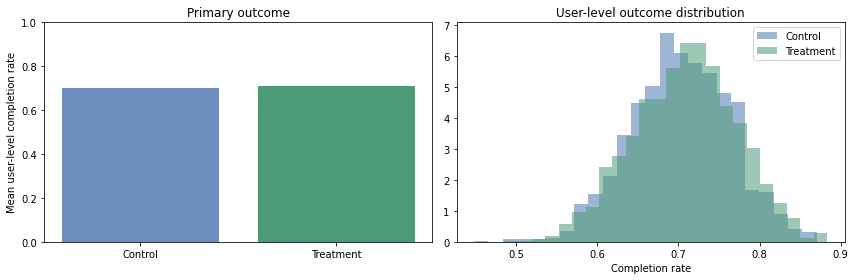

In [59]:
seg = exp.merge(merch[['merchandiser_id','platform','tenure_band']],on='merchandiser_id',how='left',validate='many_to_one')
seg_user=seg.groupby(['merchandiser_id','group','city','platform','tenure_band']).all_required_complete.mean().reset_index(name='rate')
seg_summary=seg_user.groupby(['platform','group']).rate.agg(['mean','count']).unstack('group')
seg_summary['difference_pp']=(seg_summary[('mean','treatment')]-seg_summary[('mean','control')])*100
display(seg_summary)
fig, axes=plt.subplots(1,2,figsize=(12,4))
means=user_metric.groupby('group').completion_rate.mean().reindex(['control','treatment'])
axes[0].bar(['Control','Treatment'],means.values,color=['#6c8ebf','#4d9b76'])
axes[0].set_ylim(0,1); axes[0].set_ylabel('Mean user-level completion rate'); axes[0].set_title('Primary outcome')
axes[1].hist(c,bins=24,alpha=.65,label='Control',color='#6c8ebf',density=True)
axes[1].hist(t,bins=24,alpha=.55,label='Treatment',color='#4d9b76',density=True)
axes[1].set_title('User-level outcome distribution'); axes[1].set_xlabel('Completion rate'); axes[1].legend()
plt.tight_layout()


## 10. Интерпретация и рекомендация

Используем заранее согласованное правило: масштабирование требует (1) статистически значимого положительного эффекта по основной метрике, (2) эффекта не ниже бизнес-MDE +1 п.п. и (3) отсутствия ухудшения защитных метрик. Иначе — не раскатывать на всех пользователей; оценить доверительный интервал, внедрение и стоимость дополнительного теста.


In [60]:
if (welch.pvalue < alpha) and (delta >= mde) and guardrail_pass and visit_exposure_rate >= .85:
    decision='Рекомендация: рассмотреть поэтапный запуск с мониторингом после проверки экономики продукта.'
elif not guardrail_pass or visit_exposure_rate < .85:
    decision='Рекомендация: не масштабировать; нарушен как минимум один заранее заданный guardrail или порог внедрения.'
elif (welch.pvalue < alpha) and (delta < mde):
    decision='Рекомендация: эффект статистически заметен, но ниже бизнес-MDE; не масштабировать без обоснования экономики.'
elif ci[1] < mde:
    decision='Рекомендация: не объявлять победителя. Верхняя граница 95% ДИ ниже бизнес-MDE; оставить контроль для заданного порога ценности.'
else:
    decision='Рекомендация: не объявлять победителя; дополнительный тест оправдан, если 95% ДИ всё ещё включает бизнес-MDE.'
print(decision)
print(f'Δ={delta:+.2%}, 95% ДИ [{ci[0]:+.2%}, {ci[1]:+.2%}], p={welch.pvalue:.4f}; MDE={mde:.1%}.')


Рекомендация: эффект статистически заметен, но ниже бизнес-MDE; не масштабировать без обоснования экономики.
Δ=+0.54%, 95% ДИ [+0.09%, +0.98%], p=0.0194; MDE=1.0%.


## 11. Ограничения и следующий эксперимент

- Команда содержит сотрудников обеих групп. Экран персональный, но обмен практиками может вызвать spillover; в реальном продукте нужно подтвердить это интервью/логами или рандомизировать команды и учитывать кластеризацию.
- Новая версия может менять поведение только у фактически экспонированных пользователей; основной ITT не заменяем post-hoc анализом exposed.
- До следующего запуска зафиксировать метрики, MDE, окно наблюдения, исключения, правила остановки и план множественных сравнений. Проверить SRM по ежедневным назначениям, стабильность логирования, версии приложения и календарные эффекты.
- Для оценки времени визита использовать заранее определённые правила валидности и устойчивые метрики; здесь duration приведена как защитная диагностика.


## 12. Словарь таблиц

- `merchandisers.csv` — характеристики пользователей и команда.
- `experiment_assignments.csv` — постоянное назначение 1:1 и strata.
- `visits.csv` — плановые визиты, фактические времена и исходный статус; содержит небольшое количество точных транспортных дублей для практики QA.
- `tasks.csv` — обязательные задачи в рамках визита и их статусы.
- `events.csv` — события открытия экранов и визитов.
- `outlets.csv`, `projects.csv` — справочники торговых точек и проектов-клиентов.

